[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phildani7/why-book-of-deep-learning-part-2/blob/main/notebooks/ch60_LabCh60_Shrinking_A_Model.ipynb)

**The Why Book of Deep Learning, Part 2** by Dr. Philemon Paul Daniel

**Chapter 60: Smaller Models: Quantization, Pruning and Distillation** (Part XIII: Small, Fast and Shipped).

* Read this chapter free online: [www.micyaai.com/books/why-deep-learning-2/read.html?ch=60](https://www.micyaai.com/books/why-deep-learning-2/read.html?ch=60)
* Part 1 of the book and its notebooks: [github.com/phildani7/why-book-of-deep-learning-part-1](https://github.com/phildani7/why-book-of-deep-learning-part-1)
* The simplified video course for kids: [aikids.guru](https://www.aikids.guru)
* All the notebooks for the book: [github.com/phildani7/why-book-of-deep-learning-part-2](https://github.com/phildani7/why-book-of-deep-learning-part-2)

Tested with TensorFlow 2.21 and Keras 3.14 on a laptop CPU (about five minutes or less). In Colab:
*Runtime > Run all*. It runs on the free CPU runtime; a GPU runtime works too and is usually faster, but the
printed timings and some last digits will differ from the saved outputs.

---


# Lab Ch60 - Shrinking a model
## Fewer bits, fewer weights, a smaller network: measure what each one costs

This lab goes with **Chapter 60** of *The Why Book of Deep Learning, Part 2*.

You train one "big" CNN on Fashion-MNIST and then make it smaller in three different ways. After every change
you measure the same three numbers: **size, accuracy and inference time**. A compression result quoted with
only one of the three is not a result.

| Part | Technique | Question | Steps |
|---|---|---|---|
| One | Quantisation | How few bits per weight does the model need? | 5 to 11 |
| Two | Pruning | How many weights can be removed, and what does that really save? | 12 to 16 |
| Three | Distillation | Can a much smaller network learn more from the big one than from the labels? | 17 to 19 |
| Four | Stacking | What do you get when you combine them? | 20 |

### What you will be able to do afterwards

| Skill | Where |
|---|---|
| Quantise a weight tensor by hand with a scale and a zero point, and get it back | Steps 5 and 6 |
| Predict the rounding error from the scale alone | Step 6 |
| Say why per-channel scales and clipping help, and which layers are sensitive | Steps 7 to 9 |
| Quantise activations with a calibration set, and break it with the wrong one | Step 10 |
| Fine-tune through the rounding with the straight-through estimator | Step 11 |
| Prune by magnitude, fine-tune with the holes kept, and compute the true stored size | Steps 12 to 15 |
| Test the lottery ticket hypothesis on a small network | Step 14 |
| Show that holes do not make a model faster and removed channels do | Step 16 |
| Write the distillation loss with its temperature-squared factor and test what it buys | Steps 17 to 19 |

### The rule of this lab: predict, then run

Every step asks you to **write down a prediction before you run the cell**. A wrong prediction that you
understand afterwards is worth more than a right one you guessed.

> **This lab runs on a CPU, and says so.** The saved copy was run on the author's laptop CPU with no GPU.
> Every inference time below is a measurement on the machine that ran it, quoted as a ratio to the big model.
> **Your numbers will differ.** Accuracies can also move by a few tenths of a point between machines.

> **Runtime:** about four to five minutes on a laptop CPU.

> **Honest scale:** this is a miniature: a CNN of 421,642 parameters, 30,000 small grey images, ten classes.
> Small models on easy data behave differently from large ones in two ways you will see: they have less
> redundancy to give up at very low bit widths, and a distilled student gains little when the labels are
> already plentiful. The method is the same at any size: change one thing, then measure all three numbers.

> **One more honest note.** In Part One the quantised weights are turned back into float32 before the model
> runs, so that Keras can execute them. That measures the accuracy cost of the rounding exactly. It does
> **not** make the model faster: a real speed-up needs an integer runtime, which this lab does not use.

---
## Step 1 - Imports and one seed

In [1]:
import os, time, zlib, warnings
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.get_logger().setLevel("ERROR")                      # hide TensorFlow's advisory warnings
SEED = 60
keras.utils.set_random_seed(SEED)
np.set_printoptions(precision=4, suppress=True, linewidth=110)
LAB_START = time.time()
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)
print("GPUs visible:", len(tf.config.list_physical_devices("GPU")), "(this lab is written for a CPU)")

TensorFlow 2.21.0 | Keras 3.14.1
GPUs visible: 0 (this lab is written for a CPU)


---
## Step 2 - The data

Fashion-MNIST: 28 x 28 grey images of ten kinds of clothing. To keep the lab short we train on the first
30,000 training images and test on all 10,000 test images. Short fine-tunes later use the first 15,000.

For a real run, use all 60,000 and more epochs.

In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()
N_TRAIN, N_FINE = 30_000, 15_000
x_train = x_train[:N_TRAIN, ..., None].astype("float32") / 255.0
y_train = y_train[:N_TRAIN].astype("int32")
x_test = x_test[..., None].astype("float32") / 255.0
y_test = y_test.astype("int32")
x_fine, y_fine = x_train[:N_FINE], y_train[:N_FINE]
NAMES = ["T-shirt", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

print("train:", x_train.shape, x_train.dtype, "| test:", x_test.shape)
print("images per class in the training subset:", np.bincount(y_train))

train: (30000, 28, 28, 1) float32 | test: (10000, 28, 28, 1)
images per class in the training subset: [2945 3015 2989 3017 2960 3030 3081 3021 2972 2970]


---
## Step 3 - The big model, with its parameters counted by hand

Two convolutions, each followed by pooling, then a Dense layer of 128 and a Dense layer of 10 that outputs
**logits** (no softmax: Step 17 needs the raw scores). This is the "teacher" for the rest of the lab.

> **Predict:** which layer holds most of the parameters? Roughly what fraction?

In [3]:
def build_teacher(c1=32, c2=64, d=128, name="teacher"):
    return keras.Sequential([
        layers.Input(shape=(28, 28, 1)),
        layers.Conv2D(c1, 3, padding="same", activation="relu", name="conv1"),
        layers.MaxPooling2D(name="pool1"),
        layers.Conv2D(c2, 3, padding="same", activation="relu", name="conv2"),
        layers.MaxPooling2D(name="pool2"),
        layers.Flatten(name="flatten"),
        layers.Dense(d, activation="relu", name="dense1"),
        layers.Dense(10, name="logits"),
    ], name=name)

def hand_count(c1=32, c2=64, d=128):
    return {"conv1": 3 * 3 * 1 * c1 + c1, "conv2": 3 * 3 * c1 * c2 + c2,
            "dense1": 7 * 7 * c2 * d + d, "logits": d * 10 + 10}

teacher = build_teacher()
W_INIT = teacher.get_weights()                         # the random starting weights, kept for Step 14
counts = hand_count()
P_TEACHER = sum(counts.values())
for name, n in counts.items():
    print(f"{name:7s} {n:>9,}   ({100 * n / P_TEACHER:4.1f}% of the model)")
assert teacher.count_params() == P_TEACHER == 421_642
print(f"total   {P_TEACHER:>9,}   parameters, counted by hand and confirmed by Keras")
print(f"stored as float32: {P_TEACHER} x 4 bytes = {4 * P_TEACHER:,} bytes = {4 * P_TEACHER / 1e6:.2f} MB")

conv1         320   ( 0.1% of the model)
conv2      18,496   ( 4.4% of the model)
dense1    401,536   (95.2% of the model)
logits      1,290   ( 0.3% of the model)
total     421,642   parameters, counted by hand and confirmed by Keras
stored as float32: 421642 x 4 bytes = 1,686,568 bytes = 1.69 MB


### Why we see this

`dense1` holds 95.2% of the parameters, the pattern Chapter 14 pointed out: the Dense layer after Flatten is
where the weights live. Anything that is going to shrink the file has to shrink that layer. The convolutions
hold under 5% of the weights, but each of those weights is used at every position of the image, so they do
most of the arithmetic. That difference returns in Step 16.

---
## Step 4 - Train it, and take the three measurements

Five epochs. Then the three numbers we will report for every model in this lab:

1. **size**: bytes needed to store the weights,
2. **accuracy** on the 10,000 test images, and the accuracy of the **worst class** beside it,
3. **inference time**: milliseconds per 1,000 images on this CPU. Warm up, repeat, and keep the **fastest**
   round: other programs on the machine can only make a run slower, never faster. When models are compared,
   each is timed straight after the teacher, nine times, and the median ratio is reported. The teacher is
   also timed against itself: how far that ratio is from 1.00 tells you how much to trust the others.

> **Predict:** which of the ten classes will the model find hardest?

In [4]:
LOSS = keras.losses.SparseCategoricalCrossentropy(from_logits=True)

def accuracy(model, x=x_test, y=y_test):
    """overall accuracy, accuracy of the worst class, and which class that is (all in per cent)"""
    pred = model.predict(x, batch_size=1000, verbose=0).argmax(axis=1)
    per_class = np.array([(pred[y == c] == c).mean() for c in range(10)])
    return 100 * (pred == y).mean(), 100 * per_class.min(), int(per_class.argmin())

x_time = tf.constant(x_test[:2000])
def make_runner(model):
    @tf.function(autograph=False)                       # plain tracing: no Python branches to convert
    def run(x):
        return model(x, training=False)
    run(x_time[:500])                                   # warm up: the first call builds the graph
    return run

def time_once(run):
    t = time.perf_counter()
    for i in range(0, 2000, 500):
        run(x_time[i:i + 500])
    return time.perf_counter() - t

def time_models(models, rounds=9):
    """Times every model in a dict. Returns two dicts: ms per 1,000 images (the fastest round), and the time
    relative to the FIRST model in the dict. For the ratio, the first model is timed again straight before
    each of the others, so that a busy moment on the machine hits both alike; the median ratio is kept."""
    runners = {name: make_runner(m) for name, m in models.items()}
    base = runners[next(iter(runners))]
    ms, rel = {name: [] for name in models}, {name: [] for name in models}
    for _ in range(rounds):
        for name, run in runners.items():
            t_base, t_model = time_once(base), time_once(run)
            ms[name].append(t_model); rel[name].append(t_model / t_base)
    return ({name: 1000 * float(np.min(v)) / 2 for name, v in ms.items()},
            {name: float(np.median(v)) for name, v in rel.items()})

t = time.time()
teacher.compile(optimizer=keras.optimizers.Adam(1e-3), loss=LOSS)
teacher.fit(x_train, y_train, batch_size=128, epochs=5, verbose=0)
print(f"trained in {time.time() - t:.0f} s")

W_TEACHER = teacher.get_weights()                      # the float32 weights: never changed again
ACC_T, WORST_T, c = accuracy(teacher)
MS_T = time_models({"teacher": teacher})[0]["teacher"]
print(f"size      {4 * P_TEACHER / 1e6:.2f} MB")
print(f"accuracy  {ACC_T:.2f}%   worst class: {NAMES[c]} at {WORST_T:.1f}%")
print(f"time      {MS_T:.0f} ms per 1,000 images on this CPU")

# a second copy of the architecture, used as a test bench: we load altered weights into it and measure
bench = build_teacher(name="bench")
def test_weights(weights):
    bench.set_weights(weights)
    return accuracy(bench)

trained in 45 s


size      1.69 MB
accuracy  89.24%   worst class: Shirt at 59.8%
time      61 ms per 1,000 images on this CPU


### Why we see this

Shirts are the hardest class by a long way (59.8% against 89.24% overall): a shirt, a T-shirt, a pullover and
a coat are the same outline at 28 x 28 pixels. Keep watching that second number. An average over ten classes
can hide what a change does to the weakest one.

The time is for this machine at this moment. From here on, times are reported relative to this model.

---
# Part One - Quantisation: fewer bits per weight

## Step 5 - Five weights by hand

A float32 weight uses 32 bits. We will store each weight as a small integer and keep two extra numbers for
the whole tensor, a **scale** and a **zero point**, so that

`real value ≈ scale x (integer - zero point)`

With 8 bits the integers run from -128 to 127: 256 levels. The recipe:

1. take the smallest and largest weight (and make sure the range includes 0),
2. `scale = (largest - smallest) / 255`: the gap between two neighbouring levels,
3. `zero point` = the integer that real 0.0 lands on,
4. `integer = round(weight / scale) + zero point`.

> **Predict:** for the five weights below the range is -0.62 to 0.91. What is the scale at 8 bits? What is
> the largest possible rounding error? And with 2 bits (4 levels), where does the weight -0.10 end up?

In [5]:
w5 = np.array([-0.62, -0.10, 0.00, 0.27, 0.91])

def by_hand(w, bits):
    qmin, qmax = -(2 ** (bits - 1)), 2 ** (bits - 1) - 1
    lo, hi = min(w.min(), 0.0), max(w.max(), 0.0)
    scale = (hi - lo) / (qmax - qmin)
    zero_point = int(round(qmin - lo / scale))
    q = np.clip(np.round(w / scale) + zero_point, qmin, qmax).astype(int)
    back = scale * (q - zero_point)
    print(f"{bits} bits: integers {qmin} to {qmax} ({2 ** bits} levels)   scale = {scale:.4f}   zero point = {zero_point}")
    print("  weight    ", "  ".join(f"{v:7.3f}" for v in w))
    print("  integer   ", "  ".join(f"{v:7d}" for v in q))
    print("  comes back", "  ".join(f"{v:7.3f}" for v in back))
    print("  error     ", "  ".join(f"{v:7.3f}" for v in back - w), f"  (largest possible: scale / 2 = {scale / 2:.4f})\n")

by_hand(w5, 8)
by_hand(w5, 2)

8 bits: integers -128 to 127 (256 levels)   scale = 0.0060   zero point = -25
  weight      -0.620   -0.100    0.000    0.270    0.910
  integer       -128      -42      -25       20      127
  comes back  -0.618   -0.102    0.000    0.270    0.912
  error        0.002   -0.002    0.000    0.000    0.002   (largest possible: scale / 2 = 0.0030)

2 bits: integers -2 to 1 (4 levels)   scale = 0.5100   zero point = -1
  weight      -0.620   -0.100    0.000    0.270    0.910
  integer         -2       -1       -1        0        1
  comes back  -0.510    0.000    0.000    0.510    1.020
  error        0.110    0.100    0.000    0.240    0.110   (largest possible: scale / 2 = 0.2550)



### Why we see this

At 8 bits the scale is 0.006, so no weight can come back more than 0.003 away from where it started, and
these five are all within 0.002. At 2 bits the scale is 0.51: the weight -0.10 becomes 0, and 0.27 becomes
0.51, almost twice its size.

Two things to notice. The rounding error is never more than half a step, **as long as the value lies inside
the range**. And the real value 0.0 comes back as exactly 0.0 at every bit width, because the zero point is
itself one of the integers. That is on purpose: zeros are everywhere in a network (ReLU outputs, padding,
pruned weights) and they must stay exact.

---
## Step 6 - The quantiser, the histogram and the rounding error

The same recipe as a function that works on a whole tensor. `axis=None` uses one scale for the whole tensor
(**per-tensor**). `axis=-1` gives every output channel its own scale and zero point (**per-channel**).

We apply it to the big Dense kernel (401,408 weights) and look at two pictures: where the weights are, and
what the rounding does to them.

> **Predict:** every bit you remove halves the number of levels. What happens to the typical rounding error
> each time? At 4 bits (16 levels), how many of those levels will be used by a noticeable share of the weights?

dense1 kernel: (3136, 128) float32 | range -0.356 to 0.308 | std 0.0375
share of weights with |w| < 0.01: 20.7%

bits  levels    scale    RMS error   scale/sqrt(12)   levels holding > 1% of the weights
  8     256   0.00260   0.00075     0.00075          37
  6      64   0.01053   0.00304     0.00304          14
  4      16   0.04421   0.01281     0.01276          5
  3       8   0.09473   0.02644     0.02734          3
  2       4   0.22103   0.03571     0.06380          1


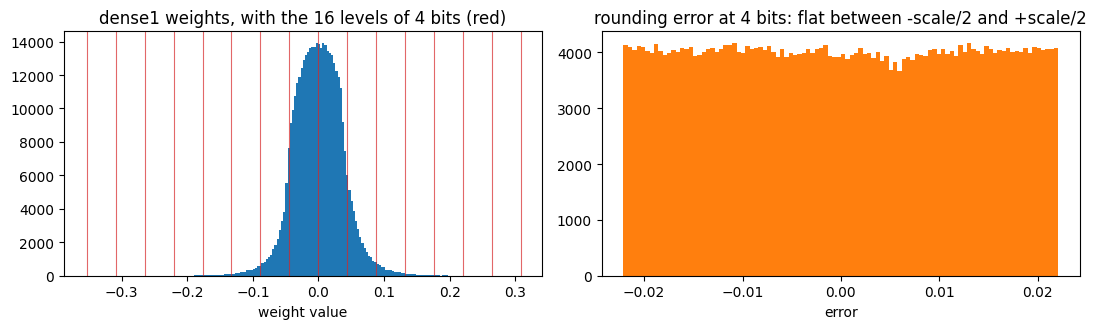

In [6]:
def quantise(w, bits, axis=None, clip_pct=None):
    """Affine quantisation of a float tensor. Returns integer codes, scale and zero point."""
    qmin, qmax = -(2 ** (bits - 1)), 2 ** (bits - 1) - 1
    if clip_pct is not None:                                   # optional: cut the tails off first
        w = np.clip(w, np.percentile(w, 100 - clip_pct), np.percentile(w, clip_pct))
    red = None if axis is None else tuple(i for i in range(w.ndim) if i != axis % w.ndim)
    lo = np.minimum(w.min(axis=red, keepdims=True), 0.0)       # the range must contain 0
    hi = np.maximum(w.max(axis=red, keepdims=True), 0.0)
    scale = (hi - lo) / (qmax - qmin)
    scale = np.where(scale == 0, 1.0, scale)                   # an all-zero channel
    zero_point = np.round(qmin - lo / scale)
    q = np.clip(np.round(w / scale) + zero_point, qmin, qmax).astype(np.int8)
    return q, scale.astype(np.float32), zero_point.astype(np.int8)

def dequantise(q, scale, zero_point):
    return (scale * (q.astype(np.float32) - zero_point.astype(np.float32))).astype(np.float32)

def fake_quant(weights, bits, axis=None, clip_pct=None, only=None):
    """quantise then dequantise every kernel in a list of weights (biases are left alone)"""
    out, k = [], 0
    for w in weights:
        if w.ndim >= 2:
            if only is None or k == only:
                w = dequantise(*quantise(w, bits, axis, clip_pct))
            k += 1
        out.append(w)
    return out

K = W_TEACHER[4]                                               # the kernel of dense1, shape (3136, 128)
print("dense1 kernel:", K.shape, K.dtype, f"| range {K.min():.3f} to {K.max():.3f} | std {K.std():.4f}")
print(f"share of weights with |w| < 0.01: {100 * (np.abs(K) < 0.01).mean():.1f}%\n")
print("bits  levels    scale    RMS error   scale/sqrt(12)   levels holding > 1% of the weights")
for bits in (8, 6, 4, 3, 2):
    q, s, z = quantise(K, bits)
    err = dequantise(q, s, z) - K
    used = (np.bincount(q.ravel().astype(int) + 128, minlength=256) > 0.01 * q.size).sum()
    print(f"{bits:3d}  {2 ** bits:6d}   {float(s.ravel()[0]):.5f}   {np.sqrt((err ** 2).mean()):.5f}     "
          f"{float(s.ravel()[0]) / np.sqrt(12):.5f}          {used}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].hist(K.ravel(), bins=200, color="tab:blue")
q4, s4, z4 = quantise(K, 4)
for level in range(-8, 8):
    ax[0].axvline(float(s4.ravel()[0]) * (level - int(z4.ravel()[0])), color="tab:red", lw=0.8, alpha=0.7)
ax[0].set_title("dense1 weights, with the 16 levels of 4 bits (red)"); ax[0].set_xlabel("weight value")
ax[1].hist((dequantise(q4, s4, z4) - K).ravel(), bins=100, color="tab:orange")
ax[1].set_title("rounding error at 4 bits: flat between -scale/2 and +scale/2"); ax[1].set_xlabel("error")
plt.tight_layout(); plt.show()

### Why we see this

**The error follows the scale.** If rounding errors are spread evenly between minus half a step and plus half
a step, their root-mean-square size is `scale / sqrt(12)`, about 0.29 of a step. The measured error matches
that at 8, 6 and 4 bits. Remove one bit and the scale doubles, so the error doubles. (At 3 and 2 bits the
formula overestimates, because the steps are now wider than the bell of weights and most weights sit close to
one level.)

**Most of the ruler is wasted.** The scale is set by the two most extreme weights, -0.356 and 0.308, but the
weights are a narrow bell with a standard deviation of 0.0375. So at 8 bits only 37 of the 256 levels hold
more than 1% of the weights each, at 4 bits 5 of the 16, and at 2 bits a single level holds nearly all of
them. The red lines in the left-hand plot show it: most levels sit out in the empty tails.

---
## Step 7 - Accuracy against bits, per-tensor and per-channel

Now the question that matters: what does the rounding do to the model? For each bit width we quantise all
four kernels, turn them back into float32 so Keras can run them, and measure test accuracy. We do it with
one scale per tensor and with one scale per output channel. We also try float16, the gentle option.

> **Predict:** at which bit width does accuracy first fall by more than one point? Does per-channel help
> more at 8 bits or at 3 bits?

float32 (the original)         89.24%   worst class  59.8%


float16                        89.24%   worst class  59.8%

bits   per-tensor  (worst class)    per-channel  (worst class)


  8      89.19%     ( 59.4%)          89.19%     ( 59.8%)


  6      89.15%     ( 58.4%)          89.25%     ( 59.9%)


  4      88.77%     ( 62.5%)          89.20%     ( 60.6%)


  3      86.46%     ( 53.6%)          87.35%     ( 42.8%)


  2      66.50%     (  0.9%)          83.31%     ( 52.5%)

conv2: range of the whole tensor 0.765 | per channel: narrowest 0.286, median 0.428, widest 0.642

dense1: range of the whole tensor 0.663 | per channel: narrowest 0.090, median 0.359, widest 0.576


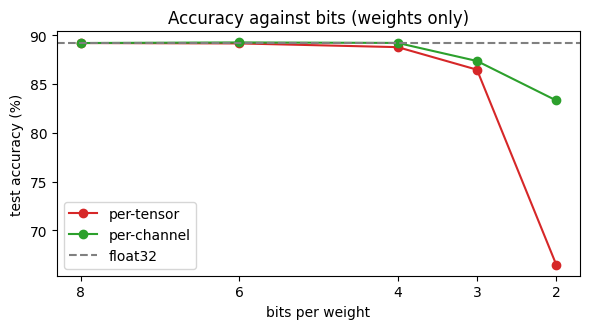

In [7]:
BITS = (8, 6, 4, 3, 2)
acc_bits = {"per-tensor": [], "per-channel": []}
print(f"float32 (the original)        {ACC_T:6.2f}%   worst class {WORST_T:5.1f}%")
a16, w16, _ = test_weights([w.astype(np.float16).astype(np.float32) for w in W_TEACHER])
print(f"float16                       {a16:6.2f}%   worst class {w16:5.1f}%\n")
print("bits   per-tensor  (worst class)    per-channel  (worst class)")
for bits in BITS:
    a1, w1, _ = test_weights(fake_quant(W_TEACHER, bits, axis=None))
    a2, w2, _ = test_weights(fake_quant(W_TEACHER, bits, axis=-1))
    acc_bits["per-tensor"].append(a1); acc_bits["per-channel"].append(a2)
    print(f"{bits:3d}     {a1:6.2f}%     ({w1:5.1f}%)         {a2:6.2f}%     ({w2:5.1f}%)")

# why per-channel can help: the channels of one layer do not share a range
for name, idx in (("conv2", 2), ("dense1", 4)):
    k = W_TEACHER[idx]
    rng_c = k.reshape(-1, k.shape[-1]).max(axis=0) - k.reshape(-1, k.shape[-1]).min(axis=0)
    print(f"\n{name}: range of the whole tensor {k.max() - k.min():.3f} | per channel: narrowest {rng_c.min():.3f}, "
          f"median {np.median(rng_c):.3f}, widest {rng_c.max():.3f}")

plt.figure(figsize=(6, 3.4))
for name, col in (("per-tensor", "tab:red"), ("per-channel", "tab:green")):
    plt.plot(BITS, acc_bits[name], "o-", color=col, label=name)
plt.axhline(ACC_T, color="grey", ls="--", label="float32")
plt.gca().invert_xaxis(); plt.xticks(BITS); plt.xlabel("bits per weight"); plt.ylabel("test accuracy (%)")
plt.legend(); plt.title("Accuracy against bits (weights only)"); plt.tight_layout(); plt.show()

### Why we see this

From 32 bits down to 4, nothing happens that you can distinguish from noise: a tenth of a point is ten images
out of 10,000. float16 gives the same accuracy to every printed digit. The cost appears at 3 bits (86.46%
per tensor) and becomes a collapse at 2 bits (66.50%).

**Per-channel scales matter most when bits are scarce.** At 8 bits the two columns are the same. At 2 bits
they are 66.50% and 83.31%. The reason is in the last two lines: within `dense1` the narrowest channel spans
0.090 and the widest 0.576, while the tensor as a whole spans 0.663. With one shared scale, the narrow
channel gets less than a seventh of the levels. With its own scale it gets all of them.

**Look at the worst class.** At 3 bits per channel the overall accuracy fell by 1.9 points, and the weakest
class fell from 59.8% to 42.8%: 17 points. At 2 bits per tensor one class is at 0.9%: the model has all but
stopped predicting it. Top-1 accuracy alone would have told you a much milder story.

**Honest scale.** This small model on this easy data survives 4 bits untouched. Do not carry that threshold
to another model. Measure it.

---
## Step 8 - One outlier stretches the ruler; clipping puts it back

The scale is set by the smallest and the largest weight. So a single unusually large weight makes every
level wider for all the others. We plant one: a weight ten times larger than any other in `dense1`. Then we
quantise at 4 bits and at 3 bits per tensor, without and with **clipping** (cut the range at the 0.05th and
99.95th percentile before choosing the scale, so the outlier saturates at the last level).

> **Predict:** the outlier is one weight in 401,408. How much can it cost at 4 bits?

In [8]:
W_OUT = [w.copy() for w in W_TEACHER]
W_OUT[4][0, 0] = 10 * np.abs(W_TEACHER[4]).max()
print(f"largest |weight| in dense1: before {np.abs(W_TEACHER[4]).max():.3f}, with the outlier {W_OUT[4].max():.3f}")
print(f"float32 accuracy with the outlier planted: {test_weights(W_OUT)[0]:.2f}%   (original {ACC_T:.2f}%)\n")
print("bits   clean, no clip   outlier, no clip   outlier, clipped   clean, clipped")
for bits in (4, 3):
    row = [test_weights(fake_quant(W_TEACHER, bits))[0], test_weights(fake_quant(W_OUT, bits))[0],
           test_weights(fake_quant(W_OUT, bits, clip_pct=99.95))[0],
           test_weights(fake_quant(W_TEACHER, bits, clip_pct=99.95))[0]]
    print(f"{bits:3d}       {row[0]:6.2f}%          {row[1]:6.2f}%            {row[2]:6.2f}%          {row[3]:6.2f}%")
s_clean = quantise(W_TEACHER[4], 4)[1].ravel()[0]; s_out = quantise(W_OUT[4], 4)[1].ravel()[0]
print(f"\nscale of dense1 at 4 bits: clean {s_clean:.4f}, with the outlier {s_out:.4f} ({s_out / s_clean:.1f} times coarser)")

largest |weight| in dense1: before 0.356, with the outlier 3.555


float32 accuracy with the outlier planted: 89.24%   (original 89.24%)

bits   clean, no clip   outlier, no clip   outlier, clipped   clean, clipped


  4        88.77%           67.65%             88.85%           88.88%


  3        86.46%           10.02%             88.95%           88.95%

scale of dense1 at 4 bits: clean 0.0442, with the outlier 0.2607 (5.9 times coarser)


### Why we see this

In float32 the planted weight changed nothing: the accuracy is still 89.24%. The damage is all in the ruler.
The range of `dense1` grew from 0.66 to 3.91, so its scale became 5.9 times coarser. At 4 bits the accuracy
fell from 88.77% to 67.65%. At 3 bits it fell to 10.02%, which is chance for ten classes: with eight levels
stretched out to reach the outlier, almost every real weight rounds to the same level.

**Clipping** fixes it. With the range cut at the 0.05th and 99.95th percentile the outlier saturates at the
last level and everything else gets fine steps again (88.85% and 88.95%).

Now read the last column: clipping helped the *clean* model as well, from 86.46% to 88.95% at 3 bits. Even
without a planted outlier, the natural tails of the bell were costing more than they were worth. Clipping
trades a large error on a few weights for a smaller error on all the others. Real quantisers choose the
clipping range to make the total error as small as possible, not to cover every value.

---
## Step 9 - Which layer is sensitive?

Quantise **one layer at a time** to very few bits and leave the other three in float32. The layer whose
rounding hurts most is the one to protect (give it more bits, or leave it in float).

> **Predict:** `dense1` holds 95% of the weights. Is it the most sensitive layer?

In [9]:
print("layer     weights     only this layer at 3 bits    only this layer at 2 bits")
for k, name in enumerate(["conv1", "conv2", "dense1", "logits"]):
    a3 = test_weights(fake_quant(W_TEACHER, 3, only=k))[0]
    a2 = test_weights(fake_quant(W_TEACHER, 2, only=k))[0]
    print(f"{name:7s} {W_TEACHER[2 * k].size:>9,}          {a3:6.2f}%                    {a2:6.2f}%")
print(f"(all layers in float32: {ACC_T:.2f}%)")

layer     weights     only this layer at 3 bits    only this layer at 2 bits


conv1         288           89.21%                     84.87%


conv2      18,432           89.03%                     84.94%


dense1    401,408           89.12%                     76.68%


logits      1,280           88.16%                     86.45%
(all layers in float32: 89.24%)


### Why we see this

Sensitivity does not follow size. At 3 bits the only layer whose rounding costs a full point is `logits`
(88.16%), which holds 1,280 weights: 0.3% of the model. Each of its weights feeds a class score directly, and
there is no later layer to average the error away. The 401,408 weights of `dense1` take 3 bits almost for free.

At 2 bits `dense1` becomes the worst (76.68%), for the reason seen in Step 6: with four levels, nearly all
of its bell of weights lands on one level. `conv1` has only 288 weights, yet rounding them to 2 bits costs 4.4
points, because every one of them is used at every position of every image.

In deeper networks the usual suspects are the same: the first layer and the last. They are small, so keeping
them at higher precision costs almost nothing in size. That is why many deployed models are quantised
unevenly.

---
## Step 10 - Activations need a ruler too, and the ruler needs calibration

So far only the weights were rounded. For a model that runs in integer arithmetic from end to end, the
**activations** (each layer's output) must be integers as well. A weight's range can be read off the weight.
An activation's range depends on the input, so it has to be **measured** by running a few hundred examples
through the model: the **calibration set**.

We simulate it: run the model layer by layer and round each layer's output to 256 levels (8 bits) between
the smallest and largest value seen during calibration. Anything outside that range is clipped.

Three calibration sets: 200 random training images; 200 images of sandals only (one class out of ten); and
200 blank images, which is what a conversion script gets when somebody passes placeholder data "to make it run".

> **Predict:** rank the three calibration sets by the accuracy of the integer model they produce. How far
> apart will the first two be?

In [10]:
def run_layers(model, x, ranges=None, bits=8, record=None):
    """forward pass one layer at a time; optionally round each weighted layer's output to 2**bits levels"""
    outs = []
    for i in range(0, len(x), 1000):
        h = tf.constant(x[i:i + 1000])
        for layer in model.layers:
            h = layer(h)
            if hasattr(layer, "kernel"):
                if record is not None:
                    lo, hi = record.get(layer.name, (0.0, 0.0))
                    record[layer.name] = (min(lo, float(tf.reduce_min(h))), max(hi, float(tf.reduce_max(h))))
                if ranges is not None:
                    lo, hi = ranges[layer.name]
                    step = (hi - lo) / (2 ** bits - 1)
                    h = tf.round((tf.clip_by_value(h, lo, hi) - lo) / step) * step + lo
        outs.append(h.numpy())
    return np.concatenate(outs)

def calibrate(x):
    rec = {}
    run_layers(bench, x, record=rec)
    return rec

rng = np.random.default_rng(SEED)
calib_good = x_train[rng.choice(N_TRAIN, 200, replace=False)]
calib_sandals = x_train[y_train == 5][:200]                   # one class only
calib_blank = np.zeros((200, 28, 28, 1), "float32")           # placeholder data

bench.set_weights(W_TEACHER)
r_good, r_sandals, r_blank = calibrate(calib_good), calibrate(calib_sandals), calibrate(calib_blank)
print("largest activation seen     " + "".join(f"{n:>10s}" for n in r_good))
for what, r in (("random training images", r_good), ("sandals only", r_sandals), ("blank images", r_blank)):
    print(f"  {what:24s}  " + "".join(f"{r[n][1]:10.2f}" for n in r_good))

def acc_from_logits(z):
    return 100 * (z.argmax(1) == y_test).mean()

print(f"\nfloat32 weights, float32 activations                      {ACC_T:6.2f}%")
print(f"float32 weights, 8-bit activations, good calibration      {acc_from_logits(run_layers(bench, x_test, r_good)):6.2f}%")
bench.set_weights(fake_quant(W_TEACHER, 8, axis=-1))
ACC_FULL_INT = acc_from_logits(run_layers(bench, x_test, r_good))
print(f"8-bit weights AND 8-bit activations, good calibration     {ACC_FULL_INT:6.2f}%   <- what an integer-only model computes")
print(f"8-bit weights AND 8-bit activations, calibrated on sandals{acc_from_logits(run_layers(bench, x_test, r_sandals)):6.2f}%")
z_bad = run_layers(bench, x_test, r_blank)
print(f"8-bit weights AND 8-bit activations, calibrated on blanks {acc_from_logits(z_bad):6.2f}%")
print(f"8-bit weights AND 4-bit activations, good calibration     {acc_from_logits(run_layers(bench, x_test, r_good, bits=4)):6.2f}%")
print("\nper-class accuracy when calibrated on blank images:")
print("  " + "  ".join(f"{NAMES[c]} {100 * (z_bad[y_test == c].argmax(1) == c).mean():.0f}%" for c in range(10)))

largest activation seen          conv1     conv2    dense1    logits
  random training images          0.67      1.58     14.11     22.77
  sandals only                    0.68      1.72     13.52     24.30
  blank images                    0.09      0.17      1.23      0.71

float32 weights, float32 activations                       89.24%


float32 weights, 8-bit activations, good calibration       89.20%


8-bit weights AND 8-bit activations, good calibration      89.13%   <- what an integer-only model computes


8-bit weights AND 8-bit activations, calibrated on sandals 89.17%


8-bit weights AND 8-bit activations, calibrated on blanks  72.92%


8-bit weights AND 4-bit activations, good calibration      85.85%

per-class accuracy when calibrated on blank images:
  T-shirt 97%  Trouser 75%  Pullover 86%  Dress 55%  Coat 47%  Sandal 99%  Shirt 20%  Sneaker 94%  Bag 89%  Ankle boot 66%


### Why we see this

With a sensible calibration set, 8-bit activations cost nothing you can measure (89.20%), and rounding the
weights and the activations together gives 89.13%. That last figure is what a model running entirely in
integers would compute. Here it is simulated in floats.

**The surprise:** calibrating on sandals alone did no harm (89.17%). Look at the table of largest activations
to see why: sandals produce nearly the same ranges as a random sample. The range of an activation is set by
the strongest responses, and those are much the same for one class as for ten in this dataset.

**Blank images are a different matter.** They produce tiny ranges (the largest logit seen was 0.71 against
22.77), every real activation above them is clipped, and the accuracy falls to 72.92%, with shirts at 20%.
Nothing warned us: the "conversion" ran without error. Calibration fails when the data is a different *kind*
of thing from what the model will see, not when it is a slightly odd sample.

Do not conclude that any real data will do. This is a small classifier whose answer is an arg-max, which
survives clipping unusually well. A model that outputs a quantity (a box, a depth, a price) has no such luck.

**Activations are fussier than weights.** 4-bit weights cost nothing in Step 7. 4-bit activations cost 3.4
points here. That is the usual pattern, and one reason 8-bit activations are the common choice even when the
weights go lower.

---
## Step 11 - Quantisation-aware training: let the model learn to live with the rounding

Step 7 quantised a model that had never seen rounding: **post-training quantisation**. At very few bits it
fell apart. The alternative is to fine-tune *with the rounding in the loop*, so the weights move to places
where rounding does less harm: **quantisation-aware training**.

There is one obstacle. Rounding is a staircase: its slope is zero almost everywhere, so no gradient passes
through it (the step-function problem of Chapter 3). The usual trick is the **straight-through estimator**:
use the rounded weights in the forward pass, then pretend the rounding was not there on the way back, and
apply the gradient to the full-precision copy of the weights. In code, for every batch:

1. remember the float weights and load their quantised version into the model,
2. compute the gradient there,
3. put the float weights back and let the optimiser update *them*.

We do it at 2 bits per tensor (four levels per layer), for one epoch on 15,000 images. For a fair
comparison, a **control**: the float32 model given the same extra epoch with no rounding.

> **Predict:** post-training quantisation at 2 bits gave the accuracy you saw in Step 7. How much of the
> loss will one epoch of quantisation-aware fine-tuning win back?

In [11]:
def finetune_control(weights, epochs=1, lr=5e-4):
    m = build_teacher(name="control"); m.set_weights(weights)
    m.compile(optimizer=keras.optimizers.Adam(lr), loss=LOSS)
    m.fit(x_fine, y_fine, batch_size=128, epochs=epochs, verbose=0)
    return m

def qat_finetune(weights, bits, axis=None, epochs=1, lr=5e-4):
    m = build_teacher(name="qat"); m.set_weights(weights)
    opt = keras.optimizers.Adam(lr)
    kernels = [v for v in m.trainable_variables if len(v.shape) >= 2]

    @tf.function(autograph=False)
    def gradients(xb, yb):
        with tf.GradientTape() as tape:
            loss = LOSS(yb, m(xb, training=True))
        return tape.gradient(loss, m.trainable_variables)

    order = np.random.default_rng(SEED)
    for _ in range(epochs):
        idx = order.permutation(N_FINE)
        for i in range(0, N_FINE - 127, 128):
            b = idx[i:i + 128]
            floats = [k.numpy() for k in kernels]                       # 1. remember the float weights
            for k, f in zip(kernels, floats):
                k.assign(dequantise(*quantise(f, bits, axis)))          #    and load the rounded ones
            g = gradients(x_fine[b], y_fine[b])                         # 2. gradient at the rounded weights
            for k, f in zip(kernels, floats):
                k.assign(f)                                             # 3. put the floats back ...
            opt.apply_gradients(zip(g, m.trainable_variables))          #    ... and update them
    return m.get_weights()

t = time.time()
control = finetune_control(W_TEACHER)
ACC_CONTROL = accuracy(control)[0]
W_QAT = qat_finetune(W_TEACHER, bits=2)
ptq2 = test_weights(fake_quant(W_TEACHER, 2))
qat2 = test_weights(fake_quant(W_QAT, 2))
print(f"float32, as trained                                  {ACC_T:6.2f}%")
print(f"float32, one more epoch (the control)                {ACC_CONTROL:6.2f}%")
print(f"2 bits, post-training quantisation                   {ptq2[0]:6.2f}%   worst class {ptq2[1]:5.1f}%")
print(f"2 bits, after one epoch of quantisation-aware tuning {qat2[0]:6.2f}%   worst class {qat2[1]:5.1f}%")
print(f"({time.time() - t:.0f} s)")

float32, as trained                                   89.24%
float32, one more epoch (the control)                 89.86%
2 bits, post-training quantisation                    66.50%   worst class   0.9%
2 bits, after one epoch of quantisation-aware tuning  85.98%   worst class  63.3%
(16 s)


### Why we see this

Same bit width, same four levels per layer, same size on disk: 66.50% after post-training quantisation,
85.98% after one epoch of quantisation-aware fine-tuning. The worst class went from 0.9% to 63.3%. All of
that came from *where the weights sit*. Training with the rounding in the loop moved them to places where
rounding does less harm.

It did not make 2 bits free. The result is 3.3 points below the float model and 3.9 below the control, which
had the same extra epoch without the rounding. And it has a price that post-training quantisation does not:
you need the training data, the training code and the time. The working order is: try post-training
quantisation first, and reach for quantisation-aware training only if that is not good enough at the bit
width you need.

---
# Part Two - Pruning: fewer weights

## Step 12 - Magnitude pruning, in one shot

Step 6 showed that most weights sit close to zero. **Magnitude pruning** sets the smallest ones to exactly
zero. We use one threshold for all four kernels together (global pruning) and try 50%, 80%, 90% and 95%
with no retraining at all: **one-shot** pruning.

> **Predict:** how much accuracy survives when half the weights are deleted? When 19 out of 20 are?
> The threshold is shared: which layer will lose the largest share of its weights?

In [12]:
SPARSITIES = (0.50, 0.80, 0.90, 0.95)

def magnitude_masks(weights, sparsity):
    """one threshold over all kernels: True = keep. Biases get None (never pruned)."""
    allk = np.concatenate([np.abs(w).ravel() for w in weights if w.ndim >= 2])
    threshold = np.quantile(allk, sparsity)
    return [(np.abs(w) > threshold) if w.ndim >= 2 else None for w in weights]

def apply_masks(weights, masks):
    return [w if m is None else (w * m).astype(np.float32) for w, m in zip(weights, masks)]

def sparsity_of(weights):
    ks = [w for w in weights if w.ndim >= 2]
    return 100 * sum((k == 0).sum() for k in ks) / sum(k.size for k in ks)

acc_oneshot, masks_at = [], {}
print("target   weights left    conv1   conv2   dense1  logits  (% of each layer removed)    accuracy  (worst class)")
for sp in SPARSITIES:
    masks = magnitude_masks(W_TEACHER, sp); masks_at[sp] = masks
    pruned = apply_masks(W_TEACHER, masks)
    a, wc, _ = test_weights(pruned)
    acc_oneshot.append(a)
    per_layer = "  ".join(f"{100 * (1 - m.mean()):5.1f}%" for m in masks if m is not None)
    left = sum(int(m.sum()) for m in masks if m is not None)
    print(f"{100 * sp:4.0f}%    {left:>9,}       {per_layer}                      {a:6.2f}%   ({wc:5.1f}%)")

target   weights left    conv1   conv2   dense1  logits  (% of each layer removed)    accuracy  (worst class)


  50%      210,704        13.2%   25.0%   51.3%   11.3%                       89.11%   ( 60.8%)


  80%       84,282        21.5%   44.6%   81.9%   19.5%                       88.71%   ( 62.9%)


  90%       42,141        29.9%   58.7%   91.7%   26.4%                       85.43%   ( 57.0%)


  95%       21,071        38.9%   73.0%   96.2%   34.0%                       79.30%   ( 20.1%)


### Why we see this

Half of the weights can be deleted, with no retraining, for 0.13 of a point. At 80% the cost is half a point.
Then comes the cliff: 85.43% at 90%, and 79.30% at 95% with the worst class down to 20.1%.

The shared threshold did something sensible on its own. It removed 96.2% of `dense1` at the top setting but
only 38.9% of `conv1`. Convolution weights are larger, because each one is reused at every position and there
are few of them. A global threshold therefore protects the small layers that Step 9 found to be sensitive. A
rule of "95% from every layer" would have left `conv1` with 14 of its 288 weights.

---
## Step 13 - Prune, then fine-tune with the holes kept

A pruned network can repair itself: the surviving weights are retrained for a short time to take over the
work of the removed ones. The removed weights must **stay** removed, so after every batch we multiply the
kernels by the mask again. One epoch on 15,000 images at each sparsity.

The fair comparison is again the control from Step 11: the unpruned model given the same extra epoch.

> **Predict:** at 95% sparsity, how many points does one epoch of fine-tuning win back?

unpruned, as trained 89.24%   |   unpruned, one more epoch (the control) 89.86%

sparsity   one-shot    + one epoch of fine-tuning  (worst class)   sparsity after fine-tuning


   50%      89.11%           89.61%              ( 68.5%)            50.0%


   80%      88.71%           89.66%              ( 64.5%)            80.0%


   90%      85.43%           89.47%              ( 63.4%)            90.0%


   95%      79.30%           87.99%              ( 60.8%)            95.0%
(21 s)


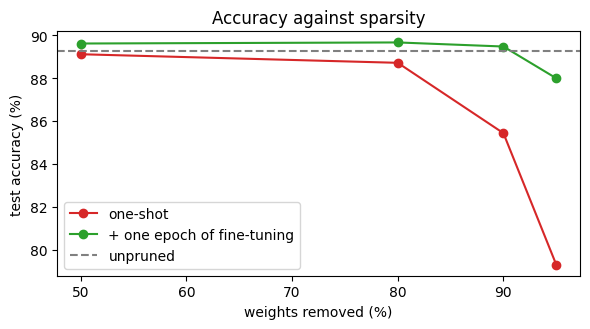

In [13]:
class KeepPruned(keras.callbacks.Callback):
    """after every batch, put the zeros back"""
    def __init__(self, masks):
        super().__init__()
        self.masks = [None if m is None else tf.constant(m, tf.float32) for m in masks]
    def on_train_batch_end(self, batch, logs=None):
        for v, m in zip(self.model.weights, self.masks):
            if m is not None:
                v.assign(v * m)

def prune_and_finetune(weights, masks, epochs=1, lr=5e-4):
    """load the weights with the masked ones set to zero, train, and keep the zeros at zero throughout"""
    m = build_teacher(name="pruned"); m.set_weights(apply_masks(weights, masks))
    m.compile(optimizer=keras.optimizers.Adam(lr), loss=LOSS)
    m.fit(x_fine, y_fine, batch_size=128, epochs=epochs, verbose=0, callbacks=[KeepPruned(masks)])
    return m.get_weights()

t = time.time()
acc_ft, W_PRUNED = [], {}
print(f"unpruned, as trained {ACC_T:.2f}%   |   unpruned, one more epoch (the control) {ACC_CONTROL:.2f}%\n")
print("sparsity   one-shot    + one epoch of fine-tuning  (worst class)   sparsity after fine-tuning")
for sp, a0 in zip(SPARSITIES, acc_oneshot):
    W_PRUNED[sp] = prune_and_finetune(W_TEACHER, masks_at[sp])
    a, wc, _ = test_weights(W_PRUNED[sp])
    acc_ft.append(a)
    print(f"{100 * sp:5.0f}%     {a0:6.2f}%          {a:6.2f}%              ({wc:5.1f}%)            {sparsity_of(W_PRUNED[sp]):.1f}%")
print(f"({time.time() - t:.0f} s)")

plt.figure(figsize=(6, 3.4))
xs = [100 * s for s in SPARSITIES]
plt.plot(xs, acc_oneshot, "o-", color="tab:red", label="one-shot")
plt.plot(xs, acc_ft, "o-", color="tab:green", label="+ one epoch of fine-tuning")
plt.axhline(ACC_T, color="grey", ls="--", label="unpruned")
plt.xlabel("weights removed (%)"); plt.ylabel("test accuracy (%)"); plt.legend()
plt.title("Accuracy against sparsity"); plt.tight_layout(); plt.show()

### Why we see this

One epoch repairs most of the damage: 85.43% becomes 89.47% at 90% sparsity, and 79.30% becomes 87.99% at 95%.

Read the first line of the output before you celebrate. Up to 90% the pruned-and-tuned models score *higher*
than the original 89.24%. That is the extra epoch, not the pruning: the unpruned control gained more from the
same epoch (89.86%). Against the control, pruning to 50%, 80%, 90% and 95% costs 0.25, 0.20, 0.39 and 1.87
points. **Whenever a compressed model is fine-tuned, compare it with the original given the same extra
training.** Otherwise you will report that compression improves accuracy.

---
## Step 14 - Two more questions about pruning: gradually or at once, and the lottery ticket

**A. Gradually or at once?** Step 13 went straight to each sparsity. The alternative is **iterative**
pruning: remove a little, fine-tune, remove more, fine-tune again. We climb 50% → 80% → 90% → 95% with one
epoch after each cut, and compare the end point with pruning to 95% in one go followed by the same four
epochs. Both get the same amount of training.

**B. The lottery ticket hypothesis** (2018) says that a dense network, at its random starting weights,
already contains a sparse sub-network that could have been trained on its own to about the same accuracy.
The sub-network is the "winning ticket". The test: take the 90% mask found in Step 12, go back to the
**original starting weights** `W_INIT` from Step 3, keep only the unmasked ones, and train that sparse
network from scratch. The control is the same mask with **fresh random** starting weights. Each is trained
for four epochs on 15,000 images, the holes kept at zero throughout.

> **Predict:** A. which reaches 95% sparsity in better shape? B. the two sparse networks have the same
> holes and the same training. Does the starting point matter?

In [14]:
t = time.time()
print("A. iterative: prune a little, fine-tune one epoch, repeat")
current = W_TEACHER
for sp in SPARSITIES:
    current = prune_and_finetune(current, magnitude_masks(current, sp))
    a, wc, _ = test_weights(current)
    print(f"   after the cut to {100 * sp:2.0f}% and one epoch: {a:6.2f}%   (worst class {wc:5.1f}%)   sparsity {sparsity_of(current):.1f}%")
W_ITER95 = current
W_SHOT95 = prune_and_finetune(W_TEACHER, masks_at[0.95], epochs=4)
ACC_ITER95, ACC_SHOT95 = test_weights(W_ITER95)[0], test_weights(W_SHOT95)[0]
print(f"   95% sparse, iterative (4 cuts, 4 epochs)   {ACC_ITER95:6.2f}%")
print(f"   95% sparse, one shot then 4 epochs         {ACC_SHOT95:6.2f}%")

print("\nB. the same 90% mask, trained from scratch for 4 epochs from two starting points")
ticket = test_weights(prune_and_finetune(W_INIT, masks_at[0.90], epochs=4, lr=1e-3))[0]
print(f"   the original starting weights (the 'ticket')    {ticket:6.2f}%")
reinit = []
for seed in (11, 12):
    keras.utils.set_random_seed(seed)
    reinit.append(test_weights(prune_and_finetune(build_teacher().get_weights(), masks_at[0.90], epochs=4, lr=1e-3))[0])
    print(f"   fresh random starting weights, seed {seed}          {reinit[-1]:6.2f}%")
keras.utils.set_random_seed(SEED)
print(f"({time.time() - t:.0f} s)")

A. iterative: prune a little, fine-tune one epoch, repeat


   after the cut to 50% and one epoch:  89.61%   (worst class  68.5%)   sparsity 50.0%


   after the cut to 80% and one epoch:  89.74%   (worst class  65.1%)   sparsity 80.0%


   after the cut to 90% and one epoch:  89.53%   (worst class  64.3%)   sparsity 90.0%


   after the cut to 95% and one epoch:  88.95%   (worst class  62.3%)   sparsity 95.0%


   95% sparse, iterative (4 cuts, 4 epochs)    88.95%
   95% sparse, one shot then 4 epochs          89.30%

B. the same 90% mask, trained from scratch for 4 epochs from two starting points


   the original starting weights (the 'ticket')     88.54%


   fresh random starting weights, seed 11           82.88%


   fresh random starting weights, seed 12           82.06%
(74 s)


### Why we see this

**A.** At this size the gradual route did not win: 88.95% against 89.30% for one cut followed by four
epochs. The difference is a third of a point from one run each, so do not read much into its sign. What it
does say is that this network recovers from a 95% cut readily, and then more training at the final sparsity
is worth as much as a gentle approach. Gradual pruning earns its keep when one big cut does damage that
fine-tuning cannot undo: deeper networks and higher sparsities.

**B.** The same holes, the same four epochs, two starting points: 88.54% from the original starting weights,
82.88% and 82.06% from fresh random ones. About six points from the starting values alone. That is what the
lottery ticket hypothesis predicts: the mask and the initial weights it was found with belong together.

It is evidence, not proof: one small network, one sparsity, one mask. And notice what the experiment needed.
The mask came from training the dense network to the end. So this is a statement about what a dense network
*contains*, not a way to avoid training it.

---
## Step 15 - What did pruning save on disk? Count the bytes

A zero stored as a float32 is four bytes, like any other number. To save space the zeros must not be stored
at all, and then something has to say **where** the surviving weights are. That is the index, and it costs
space too. Four ways to store each pruned model:

1. **dense**: every weight, zeros included, as float32,
2. **CSR** (compressed sparse row): the surviving values, a 16-bit column number for each, and one start
   position per row,
3. **bitmask**: one bit per position (kept or not), then the surviving values,
4. the dense file squeezed by a general-purpose compressor (`zlib`, the method inside zip files).

We build formats 2 and 3 for real, check that they give back the identical tensor, and count their bytes.

> **Predict:** in CSR each surviving weight costs 4 bytes for the value and 2 for its column number. Above
> what sparsity does the CSR file become smaller than the dense file? Is a 50% sparse model half the size?

In [15]:
def to_csr(k2d):
    keep = k2d != 0
    values = k2d[keep]                                                  # float32, row after row
    columns = np.nonzero(keep)[1].astype(np.uint16)                     # where each one sits in its row
    row_start = np.concatenate([[0], np.cumsum(keep.sum(axis=1))]).astype(np.uint32)
    return values, columns, row_start

def from_csr(values, columns, row_start, shape):
    out = np.zeros(shape, np.float32)
    rows = np.repeat(np.arange(shape[0]), np.diff(row_start.astype(np.int64)))
    out[rows, columns] = values
    return out

def stored_bytes(weights, value_bytes=4):
    """bytes for four storage formats; biases are always stored dense as float32"""
    dense = csr = bitmask = 0
    for w in weights:
        if w.ndim < 2:
            dense += w.nbytes; csr += w.nbytes; bitmask += w.nbytes
            continue
        k2d = w.reshape(-1, w.shape[-1]).T                              # rows = output channels
        values, columns, row_start = to_csr(k2d)
        assert np.array_equal(from_csr(values, columns, row_start, k2d.shape), k2d)   # lossless
        dense += w.size * value_bytes
        csr += values.size * value_bytes + columns.nbytes + row_start.nbytes
        bitmask += np.packbits(k2d != 0).nbytes + values.size * value_bytes
    return dense, csr, bitmask

def zlib_bytes(weights):
    return len(zlib.compress(b"".join(w.tobytes() for w in weights), 6))

print("model                dense file      CSR, 16-bit index     bitmask        dense file + zlib")
d0 = 4 * P_TEACHER
print(f"unpruned             {d0:>9,}       (not sparse)          (not sparse)    {zlib_bytes(W_TEACHER):>9,}")
SIZE_PRUNED = {}
for sp in SPARSITIES:
    d, c, b = stored_bytes(W_PRUNED[sp]); SIZE_PRUNED[sp] = (d, c, b)
    z = zlib_bytes(W_PRUNED[sp])
    print(f"pruned {100 * sp:2.0f}%           {d:>9,}       {c:>9,} ({100 * c / d0:3.0f}%)      {b:>9,} ({100 * b / d0:3.0f}%)   {z:>9,} ({100 * z / d0:3.0f}%)")

print("\nBreak-even: a sparse file is smaller than the dense one only above this sparsity")
for vb, ib, what in ((4, 4, "float32 values, 32-bit index"), (4, 2, "float32 values, 16-bit index"),
                     (1, 2, "int8 values,    16-bit index"), (1, 1, "int8 values,     8-bit index")):
    print(f"  CSR, {what}: each survivor costs {vb + ib} bytes against {vb}  ->  sparsity above {100 * ib / (vb + ib):.1f}%")
for vb, what in ((4, "float32"), (1, "int8")):
    print(f"  bitmask, {what} values: 1 bit per position against {8 * vb}  ->  sparsity above {100 / (8 * vb):.2f}%")

model                dense file      CSR, 16-bit index     bitmask        dense file + zlib
unpruned             1,686,568       (not sparse)          (not sparse)    1,565,595


pruned 50%           1,686,568       1,266,112 ( 75%)        896,428 ( 53%)     953,943 ( 57%)
pruned 80%           1,686,568         507,580 ( 30%)        390,740 ( 23%)     493,900 ( 29%)
pruned 90%           1,686,568         254,734 ( 15%)        222,176 ( 13%)     320,266 ( 19%)


pruned 95%           1,686,568         128,314 (  8%)        137,896 (  8%)     225,930 ( 13%)

Break-even: a sparse file is smaller than the dense one only above this sparsity
  CSR, float32 values, 32-bit index: each survivor costs 8 bytes against 4  ->  sparsity above 50.0%
  CSR, float32 values, 16-bit index: each survivor costs 6 bytes against 4  ->  sparsity above 33.3%
  CSR, int8 values,    16-bit index: each survivor costs 3 bytes against 1  ->  sparsity above 66.7%
  CSR, int8 values,     8-bit index: each survivor costs 2 bytes against 1  ->  sparsity above 50.0%
  bitmask, float32 values: 1 bit per position against 32  ->  sparsity above 3.12%
  bitmask, int8 values: 1 bit per position against 8  ->  sparsity above 12.50%


### Why we see this

**The dense file did not shrink at all.** 1,686,568 bytes at every sparsity. A model "pruned by 90%" and
saved the ordinary way is exactly as large as before.

**Half the weights gone is not half the size.** In CSR each survivor costs 6 bytes (4 for the value, 2 to say
where it is) against 4 in the dense file, so the 50% sparse model is 75% of the original, not 50%. At 90% it is
15%.

**The best format depends on the sparsity.** The bitmask pays a fixed 1 bit per position whether or not the
weight survived. It is the smaller format up to 90% here, and at 95% CSR overtakes it (128,314 bytes against
137,896), because CSR's cost shrinks with the number of survivors and the bitmask's does not.

**A general-purpose compressor gets part of the way** with no special format: the zlib file is 19% of the
original at 90% sparsity. But only on disk. Loaded into memory the model is dense again.

**Quantising makes the index look expensive.** Once a value costs one byte, a two-byte position costs more
than the weight it points to, and CSR with 16-bit indices only pays above 66.7% sparsity. This is why the
order of the stack matters in Step 20.

---
## Step 16 - Holes are not faster. Removed channels are.

**Unstructured** pruning (Steps 12 to 15) removes individual weights. Every tensor keeps its shape, so the
model does exactly the same multiplications as before, many of them by zero.

**Structured** pruning removes whole units: here half the filters of each convolution and half the units of
`dense1`, chosen as the ones with the smallest total absolute weight. The result is a genuinely smaller
network: 16 and 32 filters and a Dense layer of 64. We copy the surviving weights into it, measure, then
fine-tune for two epochs on 15,000 images.

> **Predict:** the 90% pruned model has a tenth of the weights. How much faster does it run on this CPU?
> The structured model has about a quarter of the weights. How much faster is that one?

In [16]:
def structured_prune(weights, c1, c2, d):
    k1, b1, k2, b2, k3, b3, k4, b4 = weights
    keep1 = np.sort(np.argsort(-np.abs(k1).sum(axis=(0, 1, 2)))[:c1])       # strongest filters of conv1
    k2 = k2[:, :, keep1, :]                                                 # conv2 loses those inputs
    keep2 = np.sort(np.argsort(-np.abs(k2).sum(axis=(0, 1, 2)))[:c2])       # strongest filters of conv2
    k3 = k3.reshape(7, 7, -1, k3.shape[-1])[:, :, keep2, :].reshape(-1, k3.shape[-1])   # Flatten order: h, w, c
    keep3 = np.sort(np.argsort(-np.abs(k3).sum(axis=0))[:d])                # strongest units of dense1
    return [k1[..., keep1], b1[keep1], k2[..., keep2], b2[keep2],
            k3[:, keep3], b3[keep3], k4[keep3, :], b4]

def multiply_adds(c1=32, c2=64, d=128):
    """multiplications per image: a convolution weight is used at every output position"""
    return {"conv1": 28 * 28 * 9 * 1 * c1, "conv2": 14 * 14 * 9 * c1 * c2, "dense1": 7 * 7 * c2 * d, "logits": d * 10}

t = time.time()
C1, C2, D1 = 16, 32, 64                                # what is kept: change these three to cut deeper
small = build_teacher(C1, C2, D1, name="structured")
P_STRUCT = sum(hand_count(C1, C2, D1).values())        # 105,866 for (16, 32, 64)
assert small.count_params() == P_STRUCT
small.set_weights(structured_prune(W_TEACHER, C1, C2, D1))
acc_struct_0 = accuracy(small)[0]
small.compile(optimizer=keras.optimizers.Adam(1e-3), loss=LOSS)
small.fit(x_fine, y_fine, batch_size=128, epochs=2, verbose=0)
ACC_STRUCT, WORST_STRUCT, _ = accuracy(small)
W_STRUCT = small.get_weights()

bench.set_weights(W_PRUNED[0.90])
ms, rel = time_models({"teacher": teacher, "holes": bench, "structured": small})
ms_teacher, ms_holes, ms_struct = ms["teacher"], ms["holes"], ms["structured"]
print("model                              parameters   non-zero    accuracy    ms per 1,000   relative time")
print(f"teacher                            {P_TEACHER:>9,}   {P_TEACHER:>8,}    {ACC_T:6.2f}%      {ms_teacher:6.1f}         1.00   (against itself: {rel['teacher']:.2f})")
nz = sum(int((w != 0).sum()) for w in W_PRUNED[0.90])
print(f"unstructured, 90% + fine-tune      {P_TEACHER:>9,}   {nz:>8,}    {acc_ft[2]:6.2f}%      {ms_holes:6.1f}         {rel['holes']:.2f}")
print(f"structured, no fine-tune           {P_STRUCT:>9,}   {P_STRUCT:>8,}    {acc_struct_0:6.2f}%")
print(f"structured + 2 epochs fine-tune    {P_STRUCT:>9,}   {P_STRUCT:>8,}    {ACC_STRUCT:6.2f}%      {ms_struct:6.1f}         {rel['structured']:.2f}")
ma_t, ma_s = multiply_adds(), multiply_adds(C1, C2, D1)
print(f"\nmultiply-adds per image: teacher {sum(ma_t.values()):,} (conv2 does {100 * ma_t['conv2'] / sum(ma_t.values()):.0f}% of them "
      f"with {100 * counts['conv2'] / P_TEACHER:.1f}% of the parameters)")
print(f"                         structured {sum(ma_s.values()):,} = {100 * sum(ma_s.values()) / sum(ma_t.values()):.0f}% of the teacher's, "
      f"with {100 * P_STRUCT / P_TEACHER:.0f}% of its parameters")
print(f"({time.time() - t:.0f} s)")

model                              parameters   non-zero    accuracy    ms per 1,000   relative time
teacher                              421,642    421,642     89.24%        37.3         1.00   (against itself: 1.01)
unstructured, 90% + fine-tune        421,642     42,375     89.47%        38.6         0.97
structured, no fine-tune             105,866    105,866     70.28%
structured + 2 epochs fine-tune      105,866    105,866     88.55%        17.7         0.44

multiply-adds per image: teacher 4,241,152 (conv2 does 85% of them with 4.4% of the parameters)
                         structured 1,117,056 = 26% of the teacher's, with 25% of its parameters
(8 s)


### Why we see this

**Holes are not faster.** The 90% sparse model takes the same time as the teacher (the ratio stays
within a few hundredths of 1.0 from run to run). Multiplying by zero takes as long as multiplying by anything else, and
the library routines that do dense matrix arithmetic do not look for zeros. Unstructured sparsity becomes
speed only on a runtime or a chip built to skip them.

**Removed channels are.** The structured model runs in about half the time. It also needed more repair:
70.28% straight after the cut (deleting 90% of individual weights left 85.43%), and 88.55% after two epochs,
0.7 below the original and 1.3 below the control.

**A quarter of the parameters is not a quarter of the time.** The structured model has 25% of the parameters
and 26% of the multiply-adds, and takes about half the time, not a quarter. Look at where the arithmetic is: `conv2` holds
4.4% of the teacher's parameters and does 85% of its multiply-adds. Parameters measure the file. They do not
measure the work, and the work does not fully measure the time either: every layer has a fixed overhead that
does not shrink with its width (Chapter 59).

---
# Part Three - Distillation: a smaller network that copies the big one

## Step 17 - What the teacher knows that the label does not

A label says "this is a shirt" and nothing else. The teacher's output says more: how much the image also
looks like a T-shirt, a coat or a pullover. Those small probabilities are easier to see if the logits are
divided by a **temperature** T before the softmax (Chapters 5 and 36): T = 1 is the ordinary softmax, a
larger T flattens it.

The distillation loss mixes two terms:

`loss = alpha x cross-entropy(student, true label)  +  (1 - alpha) x T² x KL(teacher at T || student at T)`

The cell prints the teacher's softened answer for one test image, then checks why the **T²** is there: it
measures the size of the gradient that the soft term sends into the student's logits, with and without it.

> **Predict:** dividing the logits by T makes the gradient of the soft term smaller. Without the T² factor,
> how many times smaller is it at T = 5 than at T = 1: about 5 times, or more?

In [17]:
def soften(logits, T):
    z = logits / T
    z = z - z.max(axis=-1, keepdims=True)
    p = np.exp(z)
    return p / p.sum(axis=-1, keepdims=True)

t_logits_test = teacher.predict(x_test, batch_size=1000, verbose=0)
p1 = soften(t_logits_test, 1.0)
# a shirt the teacher gets right, without being certain
cands = np.where((y_test == 6) & (p1.argmax(1) == 6) & (p1.max(1) > 0.55) & (p1.max(1) < 0.75))[0]
i0 = int(cands[0])
print(f"test image {i0}: true class {NAMES[y_test[i0]]}. The teacher's answer at three temperatures:\n")
print("class        hard label     T = 1     T = 2     T = 5")
for c in np.argsort(-p1[i0]):
    row = "   ".join(f"{soften(t_logits_test[i0], T)[c]:7.3f}" for T in (1, 2, 5))
    print(f"{NAMES[c]:11s}      {int(c == y_test[i0])}        {row}")
ent = lambda p: float(-(p * np.log2(p + 1e-12)).sum(-1).mean())
print("\naverage information in the teacher's answer over the test set (bits; a hard label has 0):")
print("   " + "   ".join(f"T = {T}: {ent(soften(t_logits_test, T)):.2f}" for T in (1, 2, 5)))

def kd_loss(T, alpha, use_T2=True):
    """y_packed = [one-hot label (10 numbers), teacher logits (10 numbers)]"""
    @tf.autograph.experimental.do_not_convert           # plain TensorFlow: nothing for AutoGraph to rewrite
    def loss(y_packed, s_logits):
        hard, t_logits = y_packed[:, :10], y_packed[:, 10:]
        ce = keras.losses.categorical_crossentropy(hard, s_logits, from_logits=True)
        p_teacher = tf.nn.softmax(t_logits / T)
        kl = tf.reduce_sum(p_teacher * (tf.nn.log_softmax(t_logits / T) - tf.nn.log_softmax(s_logits / T)), axis=-1)
        return alpha * ce + (1 - alpha) * (T * T if use_T2 else 1.0) * kl
    return loss

# the gradient of the soft term alone (alpha = 0) with respect to the student's logits
s_logits = tf.Variable(np.random.default_rng(1).normal(0, 1, (1000, 10)).astype("float32"))
y_packed = tf.constant(np.concatenate([np.eye(10, dtype="float32")[y_test[:1000]], t_logits_test[:1000]], axis=1))
print("\nmean size of the soft term's gradient      T = 1      T = 2      T = 5")
for use_T2 in (False, True):
    sizes = []
    for T in (1.0, 2.0, 5.0):
        with tf.GradientTape() as tape:
            l = tf.reduce_mean(kd_loss(T, 0.0, use_T2)(y_packed, s_logits))
        sizes.append(float(tf.reduce_mean(tf.abs(tape.gradient(l, s_logits)))) * 1000)
    print(f"  {'with the T² factor   ' if use_T2 else 'without the T² factor'}                  "
          + "   ".join(f"{v:8.4f}" for v in sizes) + f"    (T = 1 is {sizes[0] / sizes[2]:.1f} times T = 5)")

test image 4: true class Shirt. The teacher's answer at three temperatures:

class        hard label     T = 1     T = 2     T = 5
Shirt            1          0.739     0.477     0.252
T-shirt          0          0.166     0.226     0.187
Pullover         0          0.046     0.119     0.145
Coat             0          0.043     0.115     0.143
Dress            0          0.005     0.039     0.093
Bag              0          0.001     0.013     0.059
Ankle boot       0          0.000     0.004     0.037
Trouser          0          0.000     0.003     0.035
Sandal           0          0.000     0.002     0.030
Sneaker          0          0.000     0.001     0.020

average information in the teacher's answer over the test set (bits; a hard label has 0):
   T = 1: 0.35   T = 2: 0.90   T = 5: 2.39

mean size of the soft term's gradient      T = 1      T = 2      T = 5
  without the T² factor                    0.1713     0.0765     0.0181    (T = 1 is 9.4 times T = 5)
  with the T² factor 

### Why we see this

The label says "Shirt". The teacher says 0.739 shirt, 0.166 T-shirt, 0.046 pullover, 0.043 coat, and under
0.001 for sandal and sneaker. Those ratios are the extra knowledge: a shirt is easy to mistake for a T-shirt
and impossible to mistake for a sandal. No label contains that.

At T = 1 only the top few classes are visible. At T = 2 they are all there. At T = 5 they are all there and
flattened towards equality. Averaged over the test set, the teacher's answer carries 0.35 bits at T = 1,
0.90 at T = 2 and 2.39 at T = 5 (the most ten classes can carry is 3.32).

**The T² factor.** Without it the gradient of the soft term is 9.4 times smaller at T = 5 than at T = 1. One
factor of 1/T is explicit in the derivative, and the gap between two flattened distributions shrinks as well.
In the limit of high temperature the two together give exactly 1/T². If you leave the factor out, `alpha` no
longer means what you set it to: at T = 5 the teacher's pull has faded to a ninth and you are training on the
labels with a decoration. With the factor, the soft term stays of the same order at every temperature.

---
## Step 18 - The student: hard labels against the teacher's soft answers

The student has no convolutions at all: Flatten, a Dense layer of 32, a Dense layer of 10. It has about one
seventeenth of the teacher's parameters. We train it from scratch four ways, on the same 30,000 images for
the same six epochs: on the labels alone, and by distillation at T = 1, 2 and 5 with `alpha = 0.1` (one
tenth of the loss from the labels, nine tenths from the teacher). Each is run with two seeds, because the
differences we are looking for are small.

> **Predict:** which of the four students is best, and by how many points?

In [18]:
def build_student(hidden=32):
    return keras.Sequential([
        layers.Input(shape=(28, 28, 1)),
        layers.Flatten(name="flatten"),
        layers.Dense(hidden, activation="relu", name="dense1"),
        layers.Dense(10, name="logits"),
    ], name="student")

P_STUDENT = 784 * 32 + 32 + 32 * 10 + 10
assert build_student().count_params() == P_STUDENT == 25_450
print(f"student: {P_STUDENT:,} parameters, {P_TEACHER / P_STUDENT:.1f} times fewer than the teacher's {P_TEACHER:,}")

t_logits_train = teacher.predict(x_train, batch_size=1000, verbose=0)

def train_student(T, alpha, seed, x=x_train, y=y_train, t_logits=t_logits_train, epochs=6):
    keras.utils.set_random_seed(seed)
    s = build_student()
    packed = np.concatenate([np.eye(10, dtype="float32")[y], t_logits], axis=1)
    s.compile(optimizer=keras.optimizers.Adam(1e-3), loss=kd_loss(T, alpha))
    s.fit(x, packed, batch_size=128, epochs=epochs, verbose=0)
    return s

t = time.time()
RECIPES = [("hard labels only", 1.0, 1.0), ("distilled, T = 1", 1.0, 0.1),
           ("distilled, T = 2", 2.0, 0.1), ("distilled, T = 5", 5.0, 0.1)]
students, mean_full = {}, {}
print("\n30,000 training images       seed 1    seed 2     mean")
for name, T, alpha in RECIPES:
    accs = []
    for seed in (1, 2):
        s = train_student(T, alpha, seed)
        accs.append(accuracy(s)[0])
        if seed == 1:
            students[name] = s
    mean_full[name] = float(np.mean(accs))
    print(f"  {name:22s}   {accs[0]:6.2f}%   {accs[1]:6.2f}%   {mean_full[name]:6.2f}%")
print(f"  teacher                                         {ACC_T:6.2f}%")
print(f"({time.time() - t:.0f} s)")

student: 25,450 parameters, 16.6 times fewer than the teacher's 421,642



30,000 training images       seed 1    seed 2     mean


  hard labels only          84.93%    84.73%    84.83%


  distilled, T = 1          84.90%    85.22%    85.06%


  distilled, T = 2          84.67%    84.73%    84.70%


  distilled, T = 5          83.90%    83.77%    83.83%
  teacher                                          89.24%
(29 s)


### Why we see this

**The honest result: here, distillation did not help.** The label-trained student averages 84.83%. The best
distilled one (T = 1) averages 85.06%, and the gap of 0.23 is smaller than the gap between its own two seeds
(84.90% and 85.22%). At T = 2 nothing changed, and at T = 5 the student is a full point *worse* (83.83%).

Two reasons, both worth remembering.

1. **Labels were not what this student was short of.** With 30,000 labelled images, a network of 25,450
   parameters and no convolutions learns everything it is able to represent. Its limit is its own size and
   shape. More information about each image cannot lift that.
2. **A high temperature gave it the wrong job.** At T = 5 the student is asked to reproduce the teacher's
   small probabilities for all ten classes. A student this small pays for that with capacity it needed for
   the main answer. When the student is far smaller than the teacher, low and middling temperatures tend to
   work best.

The student is 4.4 points below the teacher, and distillation did not close that gap.

---
## Step 19 - Where distillation earns its keep: few labels, and a class never seen

Two harder tests of the same idea.

**A. Few labels.** The student gets only 2,000 of the training images (trained for 30 epochs so that it sees
a comparable number of batches). The teacher's soft answers for those same 2,000 images are the only extra.

**B. A class never seen.** Remove every bag from the student's training set. A student trained on labels
cannot know that bags exist. A distilled student never sees a bag either, but it sees how much the teacher
thinks each *other* image resembles a bag.

> **Predict:** in B, the label-trained student scores 0% on bags. What does the distilled student score on
> a class it has never been shown?

In [19]:
t = time.time()
N_FEW = 2000
mean_few = {}
print(f"A. {N_FEW:,} training images       seed 1    seed 2     mean")
for name, T, alpha in RECIPES:
    accs = [accuracy(train_student(T, alpha, seed, x_train[:N_FEW], y_train[:N_FEW], t_logits_train[:N_FEW], epochs=30))[0]
            for seed in (1, 2)]
    mean_few[name] = float(np.mean(accs))
    print(f"  {name:22s}   {accs[0]:6.2f}%   {accs[1]:6.2f}%   {mean_few[name]:6.2f}%")

BAG = 8
no_bag = y_train != BAG
is_bag = y_test == BAG
print(f"\nB. all {int((~no_bag).sum()):,} bags removed from the student's training set ({int(no_bag.sum()):,} images left)")
print("                               all classes    bags only")
for name, T, alpha in (RECIPES[0], RECIPES[2]):
    s = train_student(T, alpha, 1, x_train[no_bag], y_train[no_bag], t_logits_train[no_bag])
    pred = s.predict(x_test, batch_size=1000, verbose=0).argmax(1)
    print(f"  {name:22s}       {100 * (pred == y_test).mean():6.2f}%      {100 * (pred[is_bag] == BAG).mean():6.2f}%")
print(f"({time.time() - t:.0f} s)")

A. 2,000 training images       seed 1    seed 2     mean


  hard labels only          81.18%    81.02%    81.10%


  distilled, T = 1          82.41%    82.10%    82.25%


  distilled, T = 2          81.71%    81.67%    81.69%


  distilled, T = 5          81.32%    80.80%    81.06%

B. all 2,972 bags removed from the student's training set (27,028 images left)
                               all classes    bags only


  hard labels only              75.16%        0.00%


  distilled, T = 2              80.96%       58.40%
(28 s)


### Why we see this

**A. Few labels.** With 2,000 images the label-trained student averages 81.10% and the student distilled at
T = 1 averages 82.25%: a gain of 1.15 points, and both seeds agree. The teacher's answers for the same 2,000
images were the only difference. When labels are scarce, each soft answer is worth more than its label.

**B. A class never seen.** Trained on labels, the student scores 0% on bags, as it must. Distilled, it gets
58.40% of the test bags right **without ever having seen one**, and its overall accuracy rises from 75.16%
to 80.96%. It learnt what a bag is from how much the teacher thought other things resembled bags.

So the size of the gain depends on what the student is missing. Distillation pays most when

- the teacher can label far more data than you have labels for (unlabelled data is cheap),
- the labels are few, noisy or incomplete,
- the teacher is much better than anything the student could reach from the labels alone.

All three hold when a small language model is distilled from a large one. None of them held in Step 18.

---
# Part Four - Stacking

## Step 20 - Combine them, and fill in the table

The three techniques shrink different things, so they stack. Two pipelines:

- **teacher → prune 90% and fine-tune → 8-bit weights**, stored as a bitmask plus one byte per survivor,
- **teacher → distil a student → 8-bit weights**.

Every row below is measured: the bytes are counted from the arrays that would be written, the accuracy is on
the 10,000 test images, and the time is the median of nine paired timings on this CPU, relative to the teacher.

Remember what the time column can and cannot show. The quantised rows hold their weights as float32 again
when they run, and the unstructured-pruned rows still multiply by their zeros, so neither can be faster
here. Only the rows with a smaller architecture do less arithmetic.

> **Predict:** which row is the smallest? Which is the fastest? Is any row better than another on all three
> numbers at once?

model                               bytes    x smaller   accuracy   worst class   relative time
teacher, float32                 1,686,568       1.0       89.24%      59.8%          1.00
teacher, float16                   843,284       2.0       89.24%      59.8%          0.97
teacher, 8-bit per channel         423,514       4.0       89.19%      59.8%          1.00
teacher, 4-bit per channel         212,810       7.9       89.20%      60.6%          0.98
pruned 90% + tune, dense file    1,686,568       1.0       89.47%      63.4%          0.97
pruned 90% + tune, bitmask file    222,176       7.6       89.47%      63.4%          0.97
pruned 90% + tune + 8-bit           96,923      17.4       89.45%      63.4%          0.99
structured (16, 32, 64) + tune     423,464       4.0       88.55%      69.5%          0.45
structured + 8-bit                 106,842      15.8       88.56%      69.8%          0.45
student, hard labels               101,800      16.6       84.93%      51.3%         

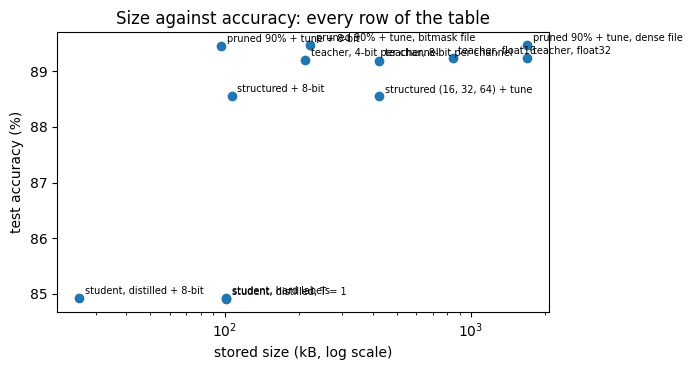

whole lab: 287 s


In [20]:
def quantised_bytes(weights, bits, axis=-1):
    """bytes on disk: kernels at `bits` each (packed), a scale and zero point per channel, float32 biases"""
    total = 0
    for w in weights:
        if w.ndim >= 2:
            q, scale, zero_point = quantise(w, bits, axis)
            total += int(np.ceil(q.size * bits / 8)) + scale.size * 4 + zero_point.size
        else:
            total += w.nbytes
    return total

def pruned_quantised_bytes(weights, bits=8, axis=-1):
    """bitmask + one packed code per surviving weight + scales, zero points and float32 biases"""
    total = 0
    for w in weights:
        if w.ndim >= 2:
            q, scale, zero_point = quantise(w, bits, axis)
            total += np.packbits(w != 0).nbytes + int(np.ceil((w != 0).sum() * bits / 8)) + scale.size * 4 + zero_point.size
        else:
            total += w.nbytes
    return total

rows, row_models = [], {}
def add_row(name, model_fn, weights, size_bytes):
    m = model_fn(); m.set_weights(weights)
    a, wc, _ = accuracy(m)
    rows.append((name, size_bytes, a, wc)); row_models[name] = m

t = time.time()
W_P90 = W_PRUNED[0.90]
W_P90_Q8 = fake_quant(W_P90, 8, axis=-1)
assert all(np.array_equal(a == 0, b == 0) for a, b in zip(W_P90, W_P90_Q8) if a.ndim >= 2)   # zeros stay zeros
best = max(("distilled, T = 1", "distilled, T = 2", "distilled, T = 5"), key=lambda n: mean_full[n])
W_S_HARD, W_S_KD = students["hard labels only"].get_weights(), students[best].get_weights()
T16 = lambda: build_teacher(C1, C2, D1)

add_row("teacher, float32", build_teacher, W_TEACHER, 4 * P_TEACHER)
add_row("teacher, float16", build_teacher, [w.astype(np.float16).astype(np.float32) for w in W_TEACHER], 2 * P_TEACHER)
add_row("teacher, 8-bit per channel", build_teacher, fake_quant(W_TEACHER, 8, -1), quantised_bytes(W_TEACHER, 8))
add_row("teacher, 4-bit per channel", build_teacher, fake_quant(W_TEACHER, 4, -1), quantised_bytes(W_TEACHER, 4))
add_row("pruned 90% + tune, dense file", build_teacher, W_P90, SIZE_PRUNED[0.90][0])
add_row("pruned 90% + tune, bitmask file", build_teacher, W_P90, SIZE_PRUNED[0.90][2])
add_row("pruned 90% + tune + 8-bit", build_teacher, W_P90_Q8, pruned_quantised_bytes(W_P90))
add_row("structured (16, 32, 64) + tune", T16, W_STRUCT, 4 * P_STRUCT)
add_row("structured + 8-bit", T16, fake_quant(W_STRUCT, 8, -1), quantised_bytes(W_STRUCT, 8))
add_row("student, hard labels", build_student, W_S_HARD, 4 * P_STUDENT)
add_row(f"student, {best}", build_student, W_S_KD, 4 * P_STUDENT)
add_row("student, distilled + 8-bit", build_student, fake_quant(W_S_KD, 8, -1), quantised_bytes(W_S_KD, 8))

ms, rel = time_models(row_models)
base_size, base_ms = rows[0][1], ms[rows[0][0]]
print("model                               bytes    x smaller   accuracy   worst class   relative time")
for name, size, a, wc in rows:
    print(f"{name:32s} {size:>9,}    {base_size / size:6.1f}      {a:6.2f}%     {wc:5.1f}%         {1.0 if name == rows[0][0] else rel[name]:5.2f}")
print(f"\nteacher: {base_ms:.0f} ms per 1,000 images on this CPU; timed against itself its ratio is {rel[rows[0][0]]:.2f}. ({time.time() - t:.0f} s)")

plt.figure(figsize=(7, 3.8))
for name, size, a, wc in rows:
    plt.scatter(size / 1000, a, color="tab:blue"); plt.annotate(name, (size / 1000, a), fontsize=7, xytext=(4, 3), textcoords="offset points")
plt.xscale("log"); plt.xlabel("stored size (kB, log scale)"); plt.ylabel("test accuracy (%)")
plt.title("Size against accuracy: every row of the table"); plt.tight_layout(); plt.show()
print(f"whole lab: {time.time() - LAB_START:.0f} s")

### Why we see this

Read the table one technique at a time, then across.

- **Fewer bits.** float16 halves the file for nothing. 8 bits gives 4.0 times and 4 bits 7.9 times, with the
  accuracy unchanged to within a tenth of a point. The ratio is a little under 4 and 8 because the biases stay
  in float32 and every channel stores a scale and a zero point.
- **Fewer weights.** The 90% pruned model saved as a dense file is not one byte smaller. In a sparse format
  it is 7.6 times smaller. With 8-bit values on top it is **17.4 times smaller at the teacher's accuracy**:
  the smallest model in the table that gives nothing up. Its time is unchanged.
- **Fewer channels.** The structured model with 8-bit weights is 15.8 times smaller and takes about half the
  time, for about 0.7 of a point.
- **A different network.** The student with 8-bit weights is 65 times smaller and about twenty times faster,
  and it is 4.3 points worse, with its weakest class at 50%.

**No row wins on all three numbers.** That is the normal state of affairs, and it is why a size quoted
without accuracy and time, or a speed-up quoted without accuracy, tells you nothing.

**The gains multiply.** 4 times from the bits and 4 times from the structure give about 16 times together.

**What the time column did not measure.** The quantised rows run in float32 here, so they show no speed-up.
On a runtime with integer arithmetic an 8-bit model is usually faster as well as smaller. This lab did not
measure that, so it does not claim it.

**What changes at full size.** Large models have far more redundancy than this one, and they tolerate 4-bit
weights and high sparsity better. Distillation, which did nothing here with plentiful labels, is one of the
main reasons small language and vision models are as good as they are. The method does not change: one
change at a time, three numbers after each, and a control for anything that was fine-tuned.

---
## Trials: change one thing at a time

Write your prediction in the middle column before you run.

| # | Change | Predict | Observe |
|---|---|---|---|
| 1 | Step 7: `BITS = (8, 6, 5, 4, 3, 2)` | Is 5 bits on the flat part or on the slope? | |
| 2 | Step 8: clip at `clip_pct=99` instead of 99.95, at 3 bits | Better still, or too much cut off? | |
| 3 | Step 10: calibrate on only 5 random training images | How close to the 200-image result? | |
| 4 | Step 11: `qat_finetune(W_TEACHER, bits=2, axis=-1)` and evaluate with `axis=-1` | Does per-channel still help after training? | |
| 5 | Step 13: `epochs=3` in `prune_and_finetune` | How much of the 95% gap to the control closes? | |
| 6 | Step 16: `C1, C2, D1 = 8, 16, 32` | Parameters, relative time and accuracy? | |
| 7 | Step 18: `build_student(hidden=128)` | Does a larger student gain more from the teacher, or less? | |
| 8 | Step 19: `BAG = 6` (remove shirts, the hardest class) | More or less than the 58% recovered for bags? | |

---
## Exercises

1. **Symmetric quantisation.** Write `quantise_symmetric(w, bits)` with the zero point fixed at 0 and the
   range set to plus and minus the largest absolute weight. Compare it with the affine version at 4 bits on
   the weights. Then explain why it would waste half its levels on the output of a ReLU.
2. **Per-layer against global pruning.** Change `magnitude_masks` to remove the same fraction from every
   kernel. Compare one-shot accuracy at 90% with the global version, and explain the difference using Step 9.
3. **Uneven bits.** Keep `conv1` and `logits` at 8 bits and give `dense1` 3 bits per channel with clipping.
   Compute the size with `quantised_bytes` (you will need a per-layer version) and measure the accuracy. Can
   you beat the uniform 4-bit row of the final table on both?
4. **Unlabelled data.** Give the student 2,000 labelled images plus the teacher's answers, with no labels,
   for all 30,000 (use `alpha = 0` on the unlabelled ones). Compare with the two rows of Step 19 A.
5. **Distil into the pruned shape.** Train a `build_teacher(16, 32, 64)` network from scratch on hard labels,
   and again by distillation at T = 2. Compare both with the structured-pruned and fine-tuned model of Step 16.
   Which route to the same architecture is best?
6. **Beyond the average.** Add Gaussian noise of standard deviation 0.1 to the test images. Measure the drop
   for the teacher, the 4-bit teacher, the 90% pruned teacher and the student. Does compression cost more
   under shift than on clean data (Chapter 63)?

---
## Cheat sheet

| Idea | The line to remember |
|---|---|
| Report | size, accuracy and time, together, with the worst class beside the average |
| Quantise | `scale = (max - min) / (levels - 1)`, `q = round(w / scale) + zero_point`, `w ≈ scale * (q - zero_point)` |
| Rounding error | at most `scale / 2`, typically `scale / sqrt(12)`; one bit fewer doubles it |
| Per-channel | one scale per output channel; matters most at low bit widths |
| Outliers | one extreme value stretches the scale for every weight: clip the range |
| Sensitive layers | the first and the last; keep them at higher precision, they are small |
| Activations | their ranges are measured on a calibration set, which must look like real inputs |
| Post-training | no data, no training; try it first |
| Quantisation-aware | forward with rounded weights, update the float copy (straight-through estimator) |
| Magnitude pruning | zero the smallest weights, fine-tune with the mask re-applied after every step |
| Control | a fine-tuned compressed model is compared with the original given the same extra training |
| Sparse storage | each survivor costs its value plus an index; a dense file saves nothing |
| Unstructured | smaller file in a sparse format, no faster on ordinary hardware |
| Structured | whole channels or units removed: a smaller dense model, genuinely faster |
| Distillation loss | `alpha * CE(student, label) + (1 - alpha) * T**2 * KL(teacher_T || student_T)` |
| When it pays | few or missing labels, plenty of unlabelled data, a teacher far better than the labels |
| Stack | distil or prune structure first, then prune weights, then quantise; measure after each |